# Stage 4. Exploratory data analysis

These figures compare logged GSE15852 microarray expression from breast tumours and patient-matched adjacent normal tissue. Inputs are the Stage 3 clean matrix and sample metadata. The optional Stage 3 QC table adds flagged-sample markers to the PCA plot.

Run the notebook from the checkout root or the notebooks folder. In Colab, make the checkout and the Stage 3 inputs available, then set the working directory to the checkout. The plotting functions are shared with the Windows runner in `scripts/run_eda.py`.

In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display

repo = Path.cwd()
if repo.name == "notebooks":
    repo = repo.parent
if not (repo / "scripts" / "run_eda.py").is_file():
    raise FileNotFoundError("Set the working directory to the project repository.")
sys.dont_write_bytecode = True
sys.path.insert(0, str(repo / "scripts"))
from run_eda import load_inputs, distribution_plot, pca_plot, heatmap_plot

expression, metadata = load_inputs()
print(f"{expression.shape[0]:,} gene symbols and {expression.shape[1]} samples")
print(f"{metadata['patient_id'].nunique()} complete patient pairs")
print(metadata["condition"].value_counts().to_string())

13,237 gene symbols and 86 samples
43 complete patient pairs
condition
Normal    43
Tumor     43


## 1. Tumour and normal expression distributions

Normal per-sample median range: 8.44–9.46
Tumor per-sample median range: 8.33–9.54


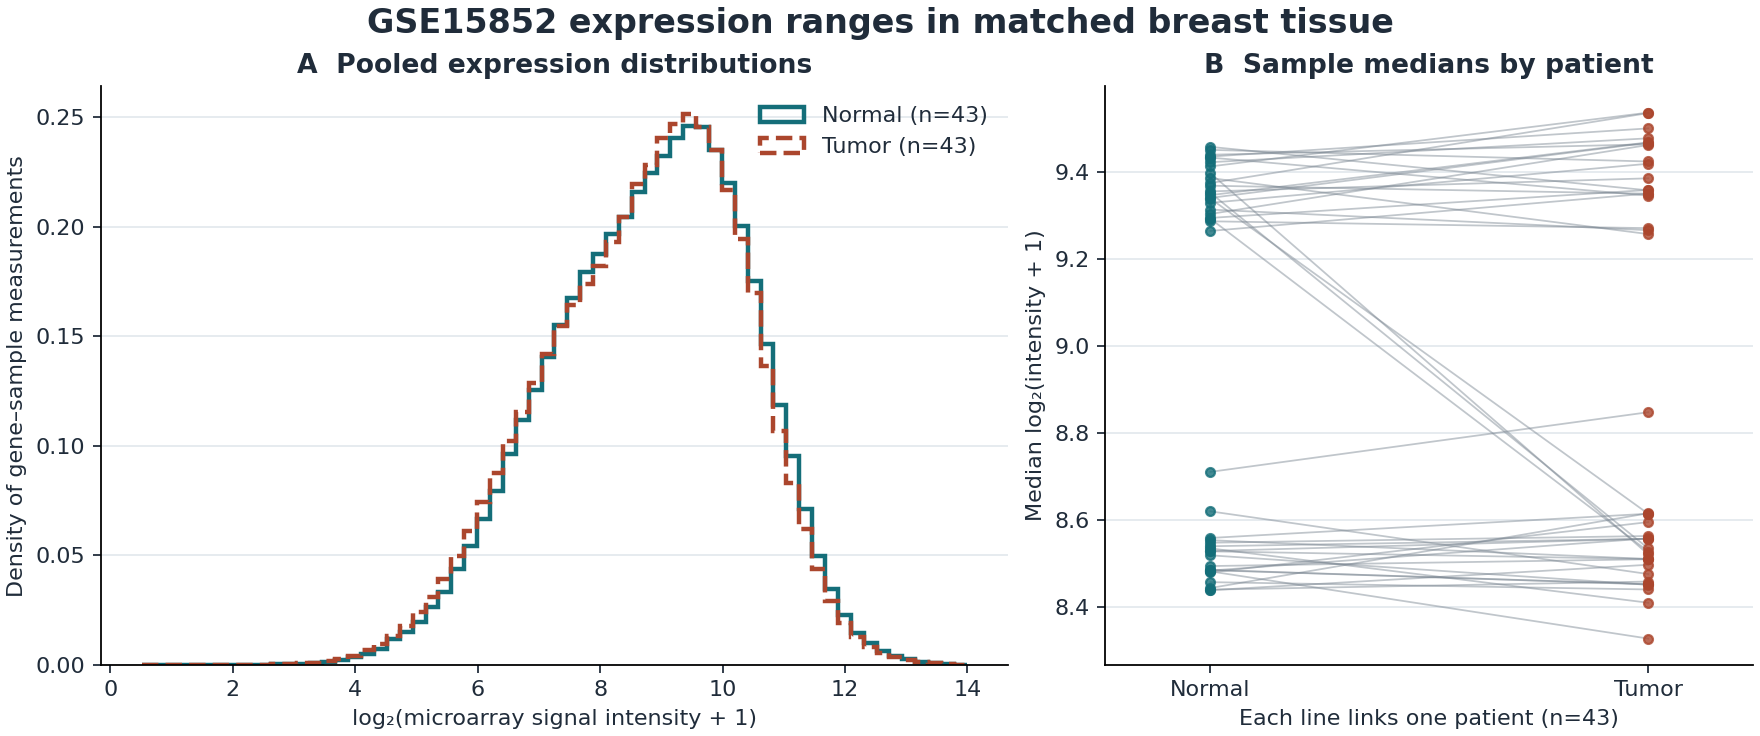

In [2]:
display(Image(filename=str(distribution_plot(expression, metadata)), width=760))

The pooled log-intensity distributions nearly overlap. The right panel links the tumour and normal sample medians for each of the 43 patients. Similar pooled distributions can still contain substantial differences in individual genes.

## 2. Sample PCA

Variance explained: PC1 33.85%, PC2 8.00%.
Furthest from the origin in PC1–PC2: GSM398074, GSM398107, GSM398154
Stage 3 flags displayed: 5.


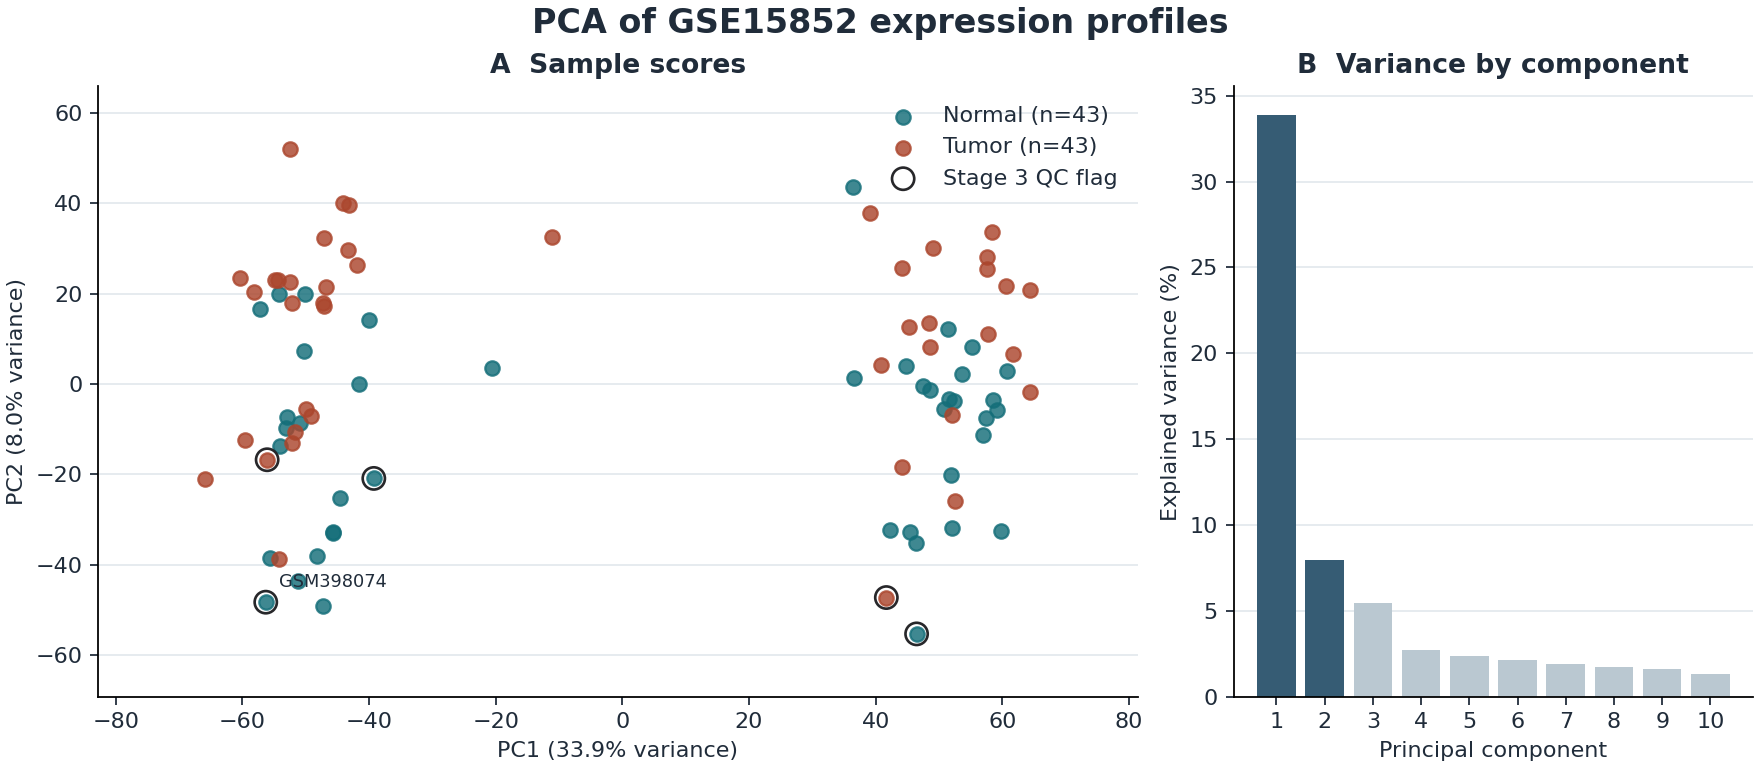

In [3]:
display(Image(filename=str(pca_plot(expression, metadata)), width=760))

PCA uses all 13,237 genes after centering each gene across samples. The variance panel shows that PC1 accounts for 33.85% and PC2 for 8.00%. Both bands along PC1 contain both tissue classes. GSM398074 is the labelled Stage 3 flag farthest from the origin. All 86 samples were retained. Batch information would be needed to investigate a technical explanation for the bands.

## 3. Heatmap of the 30 most variable genes

Largest positive median paired differences: KRT19, AGR2, KRT18
Largest negative median paired differences: RBP4, PPP1R1A, LEP
Five highest-variance genes: KRT19, CFD, AGR2, FOS, RBP4


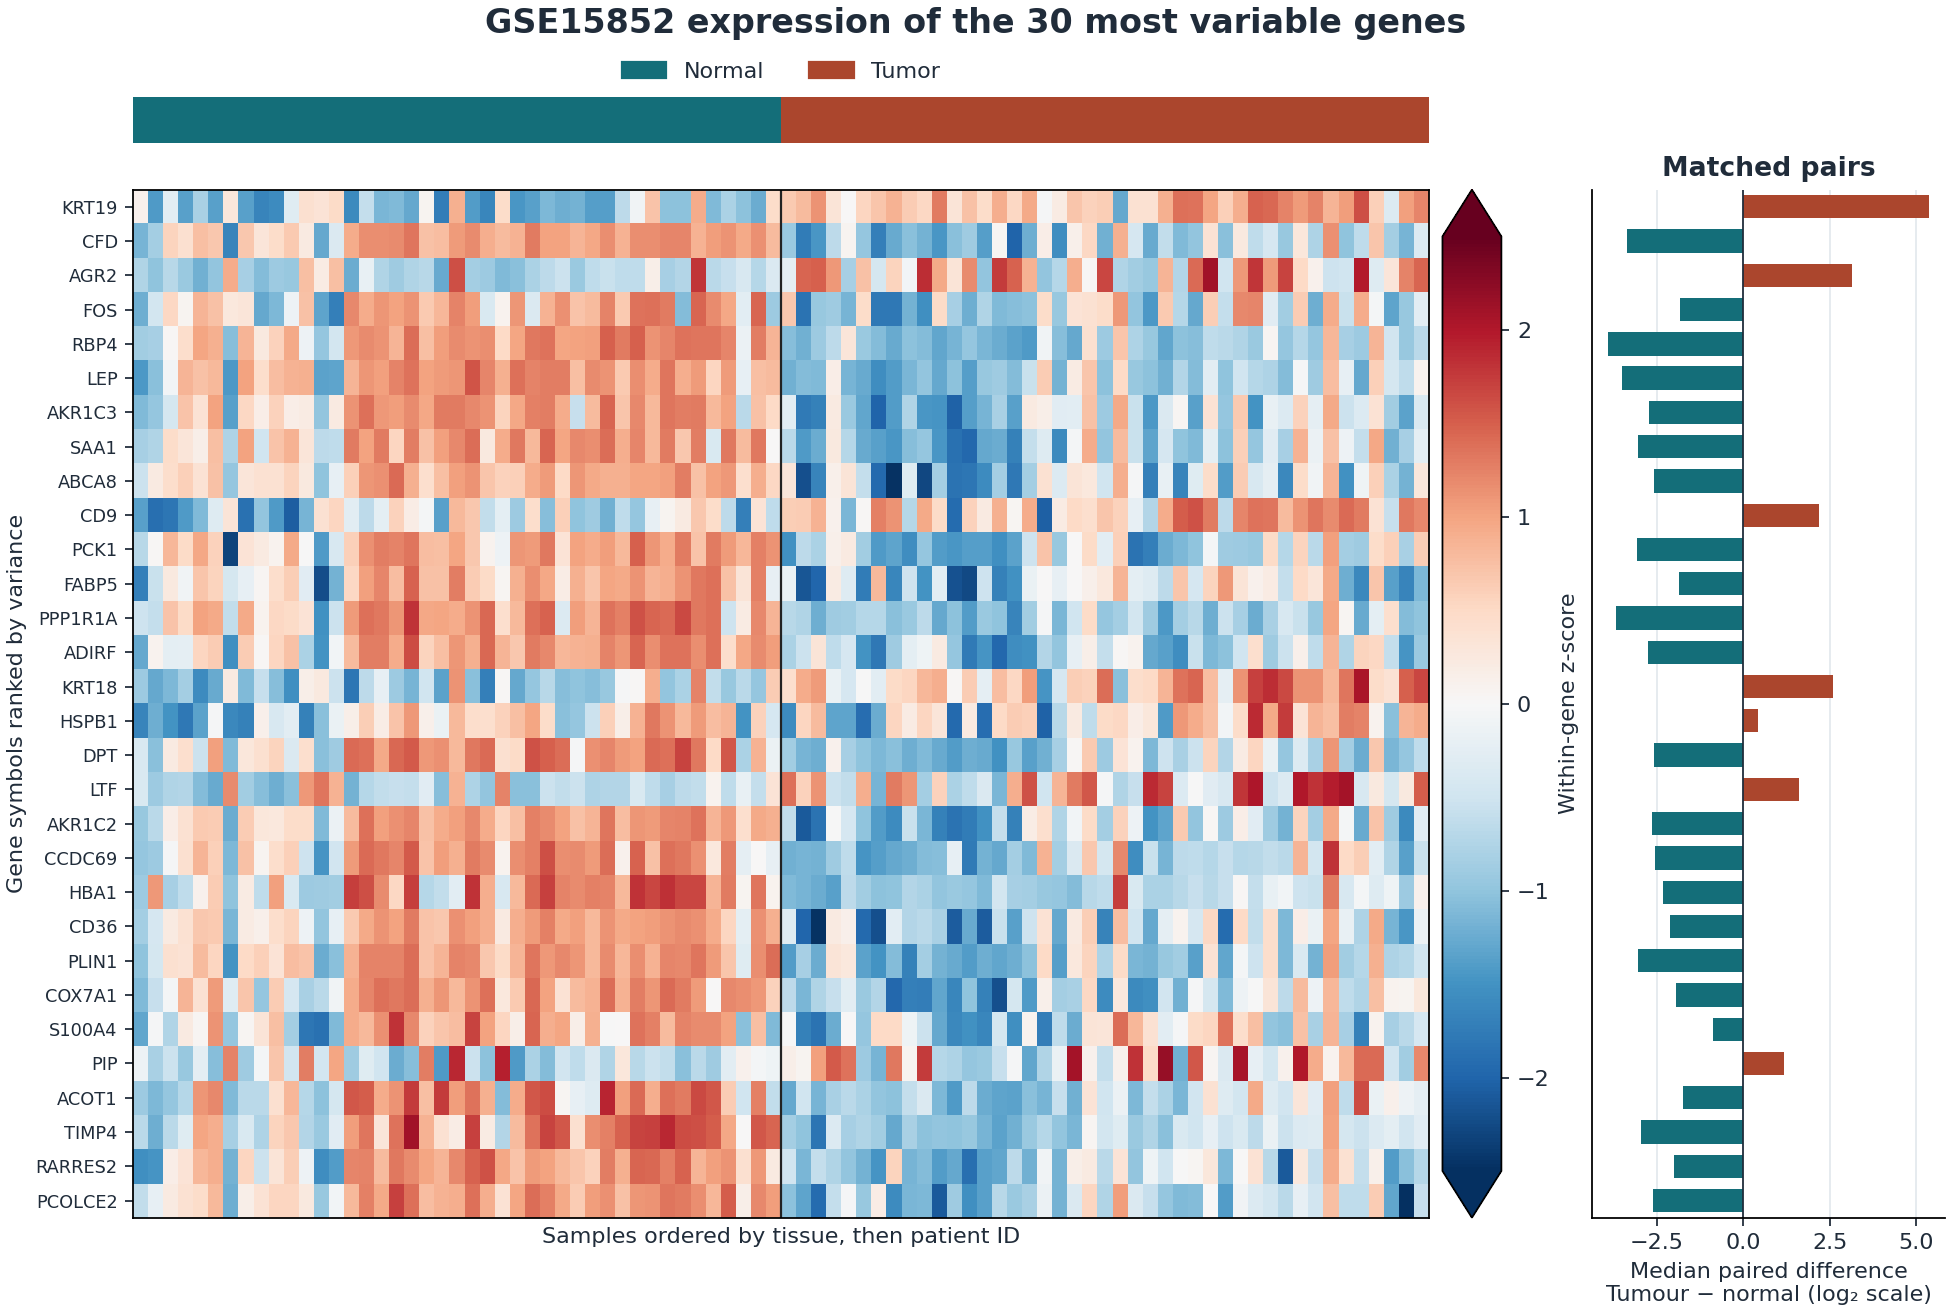

In [4]:
display(Image(filename=str(heatmap_plot(expression, metadata)), width=820))

Genes were selected by overall variance without using tissue labels. Heatmap colours represent within-gene z-scores. Each side bar shows the median of the 43 tumour-minus-normal differences for that gene on the logged scale. KRT19 and AGR2 have large positive paired differences among the displayed genes, while RBP4 and PPP1R1A have large negative differences. Stage 5 will test gene-level differences statistically.